### Этап 4. Выбросы

**Цель:** найти выбросы, понять их природу (ошибка / аномалия / реальный дорогой дом) и решить, что с ними делать.

**Что практикуем:** `quantile`, IQR-метод, `clip`, фильтрация, сравнение `mean` vs `median`, визуализация до/после.

**Данные:** `data/train_clean.csv`, `data/test_clean.csv` (результат этапа 1).

In [35]:
import json
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np


pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 100

In [2]:
train = pd.read_csv("../data/train_clean.csv")
test = pd.read_csv("../data/test_clean.csv")

print("train: ", train.shape)
print("test: ", test.shape)

train:  (1460, 81)
test:  (1459, 80)


In [3]:
with open("../columns_info.json") as f:
    cols_info = json.load(f)
    
target = cols_info["target"]
pure_num_cols = cols_info["pure_num_cols"]
pseudo_num_cols = cols_info["pseudo_num_cols"]
cat_cols = cols_info["cat_cols"]

print(f"Целевая: {target}")
print(f"Числовых: {len(pure_num_cols)}")
print(f"Псевдочисловых: {len(pseudo_num_cols)}")
print(f"Категориальных: {len(cat_cols)}")

Целевая: SalePrice
Числовых: 33
Псевдочисловых: 3
Категориальных: 43


#### Шаг 4.1. Известный кейс: `GrLivArea > 4000`

В Ames Housing есть **2 дома** с жилой площадью > 4000 кв. футов и ценой < $200k. Это аномалии — их обычно удаляют в train.

Проверить указанные данные

In [5]:
grivarea_anomalies = train[train["GrLivArea"] >4000].copy()
grivarea_anomalies = grivarea_anomalies[["Id", "GrLivArea", "SalePrice", "OverallQual", "OverallCond", "Neighborhood", "YearBuilt", "TotalBsmtSF"]].sort_values("GrLivArea", ascending = False)

print(f"Домов с GrLivArea > 4000: {len(grivarea_anomalies)}")
print()
print(grivarea_anomalies)


Домов с GrLivArea > 4000: 4

        Id  GrLivArea  SalePrice  OverallQual  OverallCond Neighborhood  \
1298  1299       5642     160000           10            5      Edwards   
523    524       4676     184750           10            5      Edwards   
1182  1183       4476     745000           10            5      NoRidge   
691    692       4316     755000           10            6      NoRidge   

      YearBuilt  TotalBsmtSF  
1298       2008         6110  
523        2007         3138  
1182       1996         2396  
691        1994         2444  


#### Вывод: 

- дома 1298 и 523 имеют большую площадь подвала больше площади жилого помещения
- большая общая площадь, высокий показатель общего состояния состояния дома, недавний год постройки, однако цена значительно ниже цены остальных домов  - **несогласованность - удалить**

In [6]:
#### статистика аномалий 

print("=== Аномалии (GrLivArea > 4000) ===")
print(grivarea_anomalies[["GrLivArea", "SalePrice", "OverallQual"]].describe().round(0))
print()
print("=== Остальные дома ===")
rest = train[train["GrLivArea"] < 4000]
print(rest[["GrLivArea", "SalePrice", "OverallQual"]].describe().round())

=== Аномалии (GrLivArea > 4000) ===
       GrLivArea  SalePrice  OverallQual
count       4.00       4.00         4.00
mean     4778.00  461188.00        10.00
std       595.00  333670.00         0.00
min      4316.00  160000.00        10.00
25%      4436.00  178562.00        10.00
50%      4576.00  464875.00        10.00
75%      4918.00  747500.00        10.00
max      5642.00  755000.00        10.00

=== Остальные дома ===
       GrLivArea  SalePrice  OverallQual
count    1456.00    1456.00      1456.00
mean     1507.00  180151.00         6.00
std       497.00   76697.00         1.00
min       334.00   34900.00         1.00
25%      1128.00  129900.00         5.00
50%      1458.00  163000.00         6.00
75%      1775.00  214000.00         7.00
max      3627.00  625000.00        10.00


#### Вывод: 

- показатель "среднее": средняя площадь у домов-аномалий примерно в 3 раза больше площади обычных домов, среднее качество дома выше на 4, однко средняя цена выше всего примерно в 2,5 раза (461188.00 vs 180151.00)
- std (разброс среди группы): у аномалий стандартное отклонение цены почти равно средней цене (333670.00  - 461188.00), значит, группа неоднородна, ее нельзя оценивать одним средним выбросом. У остальных домов разброс меньше относительно средней.
- Значительный скачок в аномалиях между 25% - 178562.00, 50% - 464875.00   - почти в 2,6 раза. Огромный разрыв между значением min - 160000.00 и max - 755000.00. 
- Разделение на дву группы: 1298, 523 и 1182 и 691, при этом площадь у домов первой группы больше, а цена ниже 

#### Визуализация: где эти дома на scatter plot

Красные точки — аномалии. Видно, что они «выпадают» из общей линейной зависимости: большая площадь, но низкая цена.

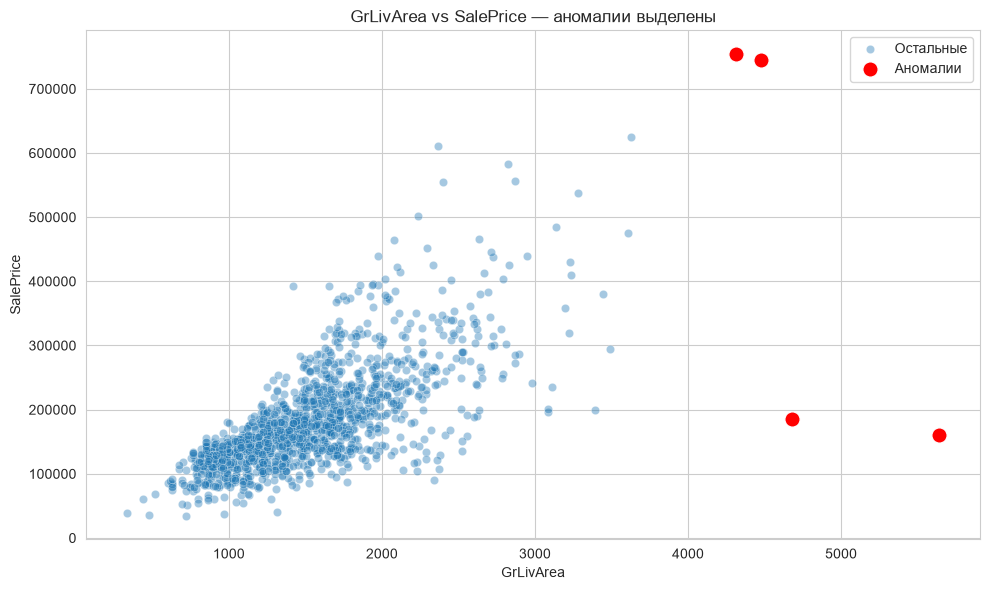

In [7]:
fig, ax = plt.subplots(figsize = (10,6))
sns.scatterplot(
    data = train, x = "GrLivArea", y= "SalePrice", alpha = 0.4, ax =ax, label = "Остальные"
)

sns.scatterplot(
    data = grivarea_anomalies, x = "GrLivArea", y= "SalePrice", color = "red", s = 120, label = "Аномалии"
)

ax.set_title("GrLivArea vs SalePrice — аномалии выделены")
ax.legend()
plt.tight_layout()
plt.show()

#### Решение: удалить аномалии из train

Это **аномалии** (низкая цена при большей площади и высоком качестве) — они искажают линейную зависимость. Удаляем из **train**. В **test** — не трогаем (там нет `SalePrice`, и удалять строки нельзя — это тестовая выборка).

In [13]:
mask_anomaly = (train["GrLivArea"]>4000) & (train["SalePrice"] <300000.00)
anomalies= train[mask_anomaly]
print(f"Аномалий(GrLivArea > 4000 И SalePrice < 300k): {len(anomalies)}")
print(anomalies[["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood"]])
print()
train_before = train.shape[0] # количество строк 
train = train[~mask_anomaly].reset_index(drop = True) # оставляем все, кроме аномалий и заново перенумеровываем строки, не сохраняя старый столбец как индекс 
print(f"Было строк: {train_before}")
print(f"Стало строк: {train.shape[0]}")
print(f"Удалено: {train_before - train.shape[0]}")

Аномалий(GrLivArea > 4000 И SalePrice < 300k): 2
        Id  GrLivArea  SalePrice  OverallQual Neighborhood
523    524       4676     184750           10      Edwards
1298  1299       5642     160000           10      Edwards

Было строк: 1460
Стало строк: 1458
Удалено: 2


### Шаг 4.2. IQR-метод для всех числовых признаков

**Формула:**
- `Q1` — 25-й перцентиль
- `Q3` — 75-й перцентиль
- `IQR = Q3 - Q1`
- `lower = Q1 - 1.5 * IQR`
- `upper = Q3 + 1.5 * IQR`

Всё, что **вне** `[lower, upper]` — выброс.

Считаем для **каждого** числового признака: сколько выбросов, какой процент, границы.

In [19]:
# функция поиска выбросов через IQR

def find_outliers_iqr(df, cols, k= 1.5):
    """
    Возвращает DataFrame: для каждого признака — Q1, Q3, IQR, lower, upper,
    количество выбросов и их процент.
    """
    rows = []
    for col in cols:
        s = df[col].dropna()
        if len(s) == 0:
            continue
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3- q1
        lower = q1- k*iqr
        upper = q3 +k*iqr
        
        n_out = ((s<lower) | (s >upper)).sum() # число выбросов 
        pct_out= n_out/len(s)*100 if len(s) > 0 else 0 # процент выбросов 
        
        rows.append({
            "feature": col, 
            "Q1": round(q1, 2), 
            "Q3": round(q3, 2), 
            "IQR": round(iqr, 2), 
            "lower": round(lower, 2), 
            "upper": round(upper, 2), 
            "n_outliers": int(n_out), 
            "pct": round(pct_out, 2)
        })
    return pd.DataFrame(rows).sort_values("pct", ascending = False).reset_index(drop= True)

# Параметр k=1.5 — классический коэффициент Тьюки. Если k=3 — более «мягкий» порог (только экстремальные выбросы).

In [ ]:
# Топ-20 признаков по проценту выбросов     

iqr_train = find_outliers_iqr(train, pure_num_cols)
print(f"Признаков с выбросами (>0): {(iqr_train["n_outliers"]> 0).sum()} из {len(iqr_train)}") 
print()
iqr_train.head(20)

Признаков с выбросами (>0): 30 из 33



,feature,Q1,Q3,IQR,lower,upper,n_outliers,pct
0,EnclosedPorch,0.00,0.00,0.00,0.00,0.00,208,14.27
1,BsmtFinSF2,0.00,0.00,0.00,0.00,0.00,167,11.45
2,OverallCond,5.00,6.00,1.00,3.50,7.50,125,8.57
3,ScreenPorch,0.00,0.00,0.00,0.00,0.00,116,7.96
4,MasVnrArea,0.00,163.75,163.75,-245.62,409.38,97,6.65
5,LotFrontage,60.00,80.00,20.00,30.00,110.00,91,6.24
6,BsmtHalfBath,0.00,0.00,0.00,0.00,0.00,82,5.62
7,GarageYrBlt,1958.00,2001.00,43.00,1893.50,2065.50,81,5.56
8,OpenPorchSF,0.00,68.00,68.00,-102.00,170.00,75,5.14
9,KitchenAbvGr,1.00,1.00,0.00,1.00,1.00,68,4.66


### Вывод:
**Группа 1**

Если Q1 = Q3 = 0 (или IQR = 0), IQR-метод не использовать (EnclosedPorch, BsmtFinSF2, ScreenPorch, BsmtHalfBath, MiscVal, LowQualFinSF, 3SsnPorch, KitchenAbvGr)



**Группа 2**

Признак - n_out - pct - комментарий

MasVnrArea	97	6.65%	облицовка камина: большинство = 0, но есть дома с большой облицовкой — реальные выбросы

LotFrontage	91	6.24%	длина фасада: есть дома с очень длинным фасадом — реальные выбросы

GarageYrBlt	81	5.56%	год постройки гаража: есть старые гаражи (до 1900) и «новые» (после 2010) — реальные выбросы

OpenPorchSF	75	5.14%	открытая веранда: есть дома с большой верандой — реальные выбросы

LotArea	66	4.53%	площадь участка: есть участки 215k кв. футов — реальные выбросы

TotalBsmtSF	59	4.05%	площадь подвала: есть дома с огромным подвалом — реальные выбросы

WoodDeckSF	32	2.19%	деревянная терраса: есть дома с большой террасой — реальные выбросы

BsmtUnfSF	29	1.99%	незавершённая площадь подвала — реальные выбросы

GrLivArea	29	1.99%	жилая площадь — реальные выбросы (уже удалили 2 аномалии)

TotRmsAbvGrd	28	1.92%	число комнат: есть дома с 12+ комнатами — реальные выбросы

Необходимо обрезать до границ, но не удалять — это потеря данных о дорогих домах



**Группа 3**

«порядковые» признаки

Признак - n_out - pct - комментарий

OverallCond	125	8.57%	оценка состояния (1–10): «выбросы» — дома с 1–3 или 8–10. Это не выбросы, а крайние оценки

BedroomAbvGr	35	2.40%	число спален: 5+ спален — «выброс», но это реальный дом

Для порядковых признаков IQR вводит в заблуждение — «крайние» значения осмысленны. Не трогаем.



In [24]:
# сравнить train и test

iqr_test = find_outliers_iqr(test, pure_num_cols)
compare_iqr = iqr_train[["feature", "pct"]].merge(iqr_test[["feature", "pct"]], on="feature", suffixes=("_train", "_test")).sort_values("pct_train", ascending=False)

compare_iqr["diff"] = (compare_iqr["pct_train"] - compare_iqr["pct_test"]).round(2)
compare_iqr.head(20)

,feature,pct_train,pct_test,diff
0,EnclosedPorch,14.27,17.20,-2.93
1,BsmtFinSF2,11.45,12.34,-0.89
2,OverallCond,8.57,8.70,-0.13
3,ScreenPorch,7.96,9.60,-1.64
4,MasVnrArea,6.65,7.13,-0.48
5,LotFrontage,6.24,7.75,-1.51
6,BsmtHalfBath,5.62,6.37,-0.75
7,GarageYrBlt,5.56,5.41,0.15
8,OpenPorchSF,5.14,5.41,-0.27
9,KitchenAbvGr,4.66,4.52,0.14


#### Вывод: 

- diff > 3 на всех строках - данные однородные, кроме EnclosedPorch (diff  = - 2.93) - ложный выброс (`IQR = 0`), игнорируем 
- **`GrLivArea` (−1.03%)** — в test больше выбросов (3.02% vs 1.99%). **Причина:** в train мы удалили 2 аномалии (`Edwards`), в test — **не удаляли** (нельзя, нет `SalePrice`). Это **прямое следствие** нашего решения
- **`LotFrontage` (−1.51%)**, **`ScreenPorch` (−1.64%)** — разница < 2%, **допустимо**.
- **Остальные признаки** — `|diff| < 1%`, **нет проблемы**.



In [29]:
# выбросы в SalePrice

s = train["SalePrice"]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3-q1
lower, upper = q1- iqr*1.5, q3 + 1.5*iqr

outliers_price = train[(s< lower )|( s> upper)].copy()

print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}")
print(f"Границы: lower - {lower:.0f}, upper - {upper:.0f}")

print(f"Выбросов: {len(outliers_price)} ({len(outliers_price)/ len(train) * 100:.1f}%)")
print()
print(outliers_price[["Id", "SalePrice", "OverallQual", "GrLivArea", "Neighborhood"]].sort_values("SalePrice", ascending = False).head(10))


Q1 = 129925, Q3 = 214000, IQR = 84075
Границы: lower - 3812, upper - 340112
Выбросов: 61 (4.2%)

        Id  SalePrice  OverallQual  GrLivArea Neighborhood
690    692     755000           10       4316      NoRidge
1181  1183     745000           10       4476      NoRidge
1168  1170     625000           10       3627      NoRidge
897    899     611657            9       2364      NridgHt
802    804     582933            9       2822      NridgHt
1045  1047     556581            9       2868      StoneBr
440    441     555000           10       2402      NridgHt
768    770     538000            8       3279      StoneBr
178    179     501837            9       2234      StoneBr
797    799     485000            9       3140      NridgHt


#### Вывод

- Выбросы - дорогие дома с высоким качеством, большой жилой площадью и элитным районом, необходимо оставить 

### Шаг 4.4. `mean` vs `median` — почему медиана устойчивее

Для каждого признака сравним среднее и медиану. Если `mean` сильно отличается от `median` — есть **асимметрия** (хвост), обычно из-за выбросов.

**Медиана** — устойчива к выбросам (ей всё равно, насколько «уехало» крайнее значение, важно только, что оно **выше** половины).

**Среднее** — чувствительно (выброс тянет его к себе).

In [37]:
# mean vs median

mean_median = pd.DataFrame({
    "mean": train[pure_num_cols].mean(), 
    "median" :train[pure_num_cols].median(), 
    "std":  train[pure_num_cols].std()
    
}).round(2)

mean_median["diffs_abs"] = (mean_median["mean"] - mean_median["median"]).abs().round(2)
mean_median["diff_pct"] = (
    (mean_median["mean"] - mean_median["median"]).abs() / mean_median["median"].replace(0, np.nan) * 100).round(1) # процентное отклонение среднего значения от медианы для каждого числового признака

mean_median = mean_median.sort_values("diff_pct", ascending = False)
mean_median.head(15)

,mean,median,std,diffs_abs,diff_pct
OpenPorchSF,46.25,24.50,65.31,21.75,88.80
Fireplaces,0.61,1.00,0.64,0.39,39.00
FullBath,1.56,2.00,0.55,0.44,22.00
BsmtUnfSF,567.10,477.50,442.09,89.60,18.80
BsmtFinSF1,438.83,382.00,432.97,56.83,14.90
OverallCond,5.58,5.00,1.11,0.58,11.60
GarageCars,1.77,2.00,0.75,0.23,11.50
LotArea,10459.94,9475.00,9859.20,984.94,10.40
TotRmsAbvGrd,6.51,6.00,1.62,0.51,8.50
1stFlrSF,1158.85,1086.00,372.04,72.85,6.70


#### Вывод:
- OpenPorchSF, Fireplaces, FullBath - наиболее сильное отклонение, однако это дискретные признаки, причина - не выбросы, а логика подсчета целых чисел 

- LotArea - значительный разброс 
- GrLivArea - достаточно ровное распределение 


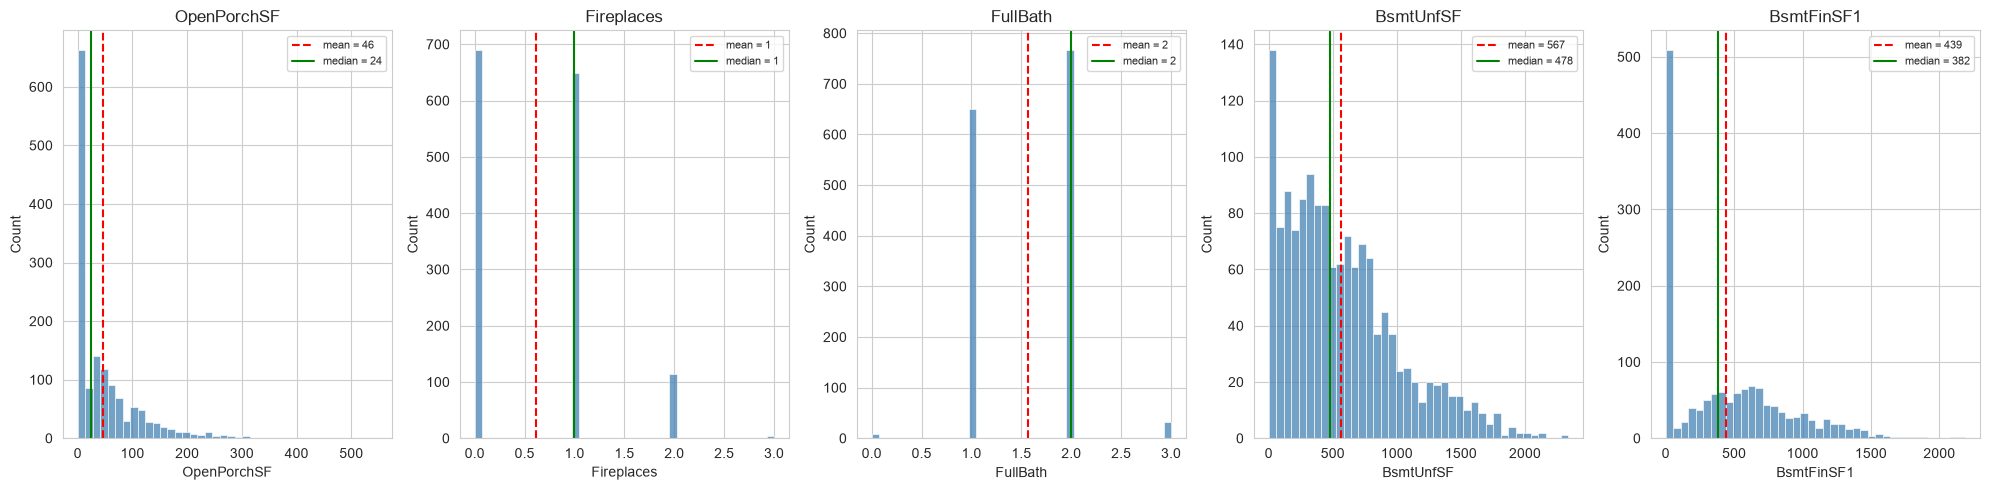

In [45]:
# визуализация mean vs median для топ-5

top5_skewed = mean_median.head(5).index.to_list()

fig, axes = plt.subplots(1, 5, figsize = (20, 5))

for ax, col in zip(axes, top5_skewed):
    sns.histplot(train[col].dropna(), bins = 40, color = "steelblue", ax=ax)
    ax.axvline(train[col].mean(), color = "red", linestyle = "--", label = f"mean = {train[col].mean():.0f}")
    ax.axvline(train[col].median(), color = "green", linestyle="-",  label=f"median = {train[col].median():.0f}")
    ax.set_title(col)
    ax.legend(fontsize = 8)
    
plt.tight_layout()
plt.show()



### Шаг 4.5. Визуализация до/после

Сравниваем boxplot и scatterplot **до** и **после** фильтрации. Важно: выбросы не «исчезают»

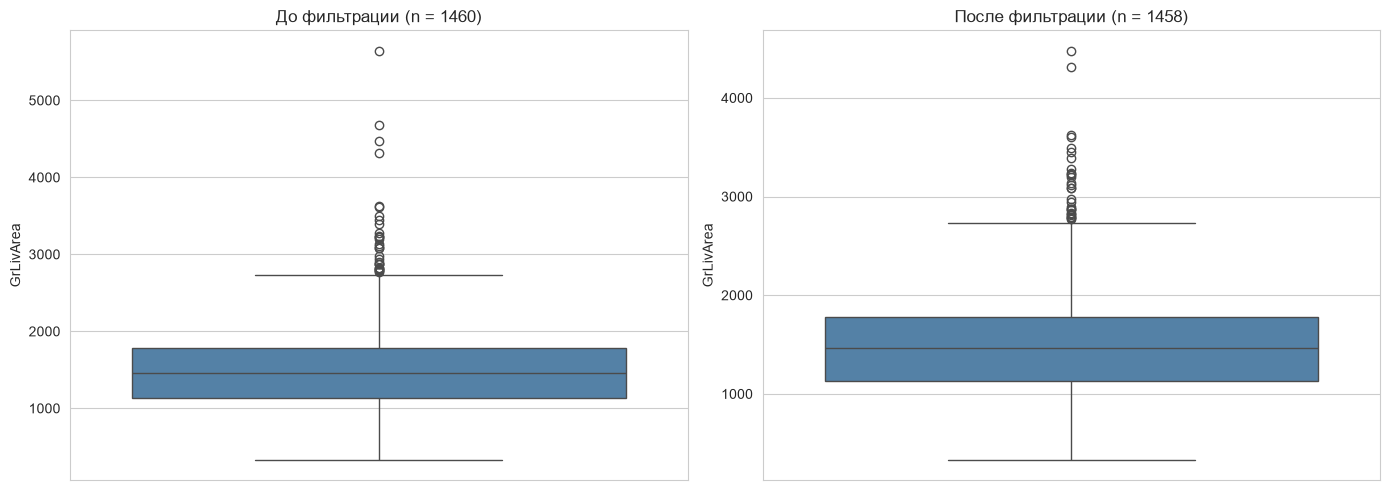

In [49]:
# boxplot до/после для GrLivArea

fig, axes = plt.subplots(1, 2, figsize = (14, 5))

train_full = pd.read_csv("../data/train_clean.csv")
sns.boxplot(data  = train_full, y = "GrLivArea", ax = axes[0], color = "steelblue" )
axes[0].set_title(f"До фильтрации (n = {len(train_full)})")


sns.boxplot(data = train, y="GrLivArea", ax=axes[1], color="steelblue")
axes[1].set_title(f"После фильтрации (n = {len(train)})")


plt.tight_layout()
plt.show()

#### Вывод: 

- n уменьшилось на 2, были удалены два дома (GrLivArea > 4000 и SalePrice < 300000)

- на левом графике видим точку со значением GrLivArea > 5000  - дом (Id 1299) с площадью 5642, ценой 160 000, у которого подвал был больше жилой прощади - ошибка данных, удален во втором графике 

- в правом графике есть выбросы -  дорогие дома в престижном районе, их не удаляли 

- сам ящик практически не изменился по высоте 

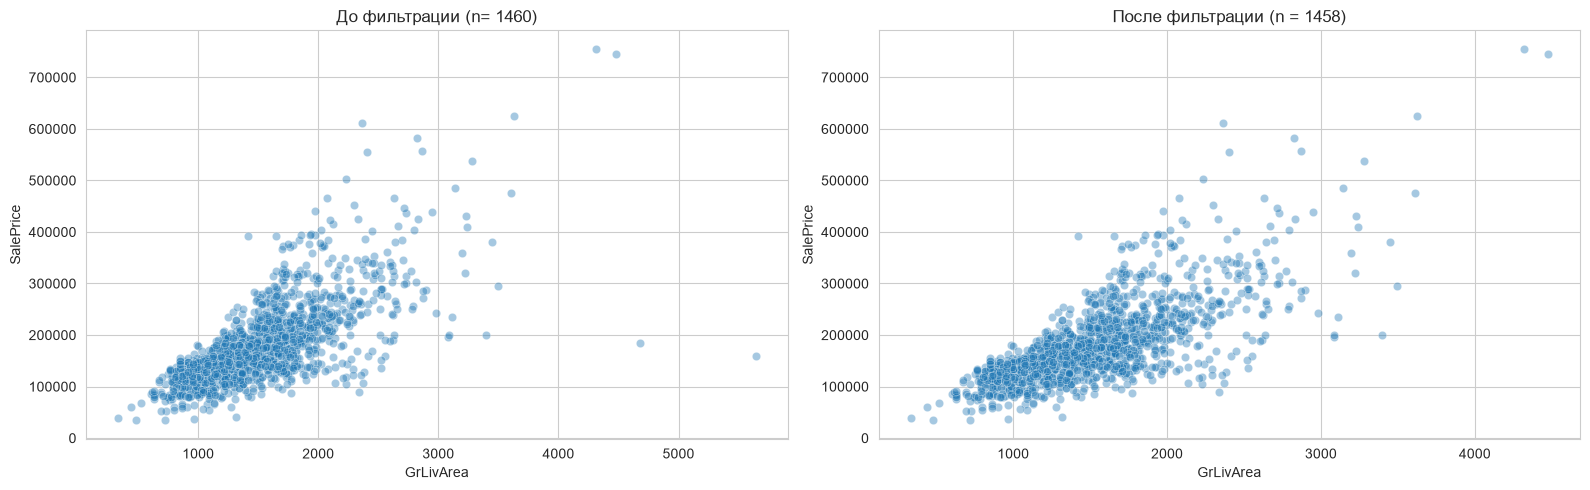

In [51]:
# scatter до/после

fig, axes = plt.subplots(1, 2, figsize = (16, 5))
sns.scatterplot(data = train_full, x = "GrLivArea", y = "SalePrice", alpha = 0.4, ax= axes[0])
axes[0].set_title(f"До фильтрации (n= {len(train_full)})")
sns.scatterplot(data = train, x = "GrLivArea", y = "SalePrice", alpha = 0.4, ax= axes[1] )

axes[1].set_title(f"После фильтрации (n = {len(train)})")

plt.tight_layout()

plt.show()


### Вывод:

- На левом графике между 4000 и 5000. находятся две точки с низкой ценой и большой площадью - удалили, на втором графике их нет

- На правом графике две точки после 4000 - дрогие дома в элитных районах - оставили

- Основная масса точек идентична

### Шаг 4.6. Clip — обрезка выбросов 

**Clip** — «обрезает» значения до границ, **не удаляя** строку. Полезно, когда:
- выброс — реальное значение, но **слишком крайнее**;
- удалять строку жалко (потеря данных);
- модель (линейная) чувствительна к крайним значениям.

**Clip vs удаление:**
- `clip` → значение становится равным границе (`upper`), строка остаётся;
- фильтр → строка удаляется целиком.

Для `SalePrice` clip **не применяем** (целевая, реальные дома). Для признаков — можно (например, `LotArea`).

Было max LotArea: 215245
Стало max LotArea_clipped: 17683
Строк обрезано: 65
Граница upper: 17683


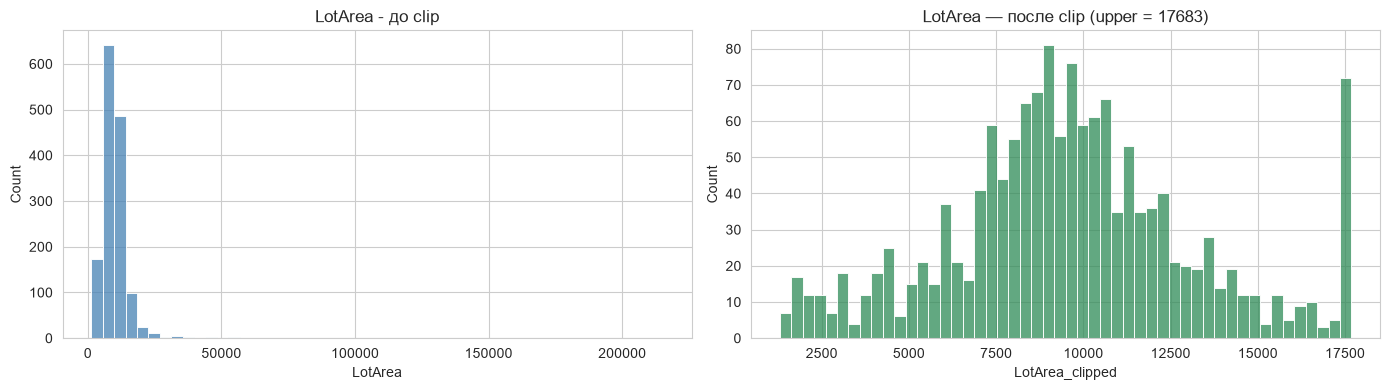

In [56]:
# пример clip для LotArea

col = "LotArea"

q1, q3 = train[col].quantile(0.25), train[col].quantile(0.75)

iqr = q3- q1
upper = q3 + 1.5* iqr

train_clip = train.copy()

train_clip[col + "_clipped"] = train_clip[col].clip(upper=upper)
print(f"Было max {col}: {train[col].max():.0f}")
print(f"Стало max {col}_clipped: {train_clip[col +"_clipped"].max():.0f}")
print(f"Строк обрезано: {(train[col] >upper).sum()}")
print(f"Граница upper: {upper:.0f}")

fig, axes = plt.subplots(1,2, figsize = (14, 4))
sns.histplot(train[col], bins = 50, ax= axes[0], color = "steelblue")
axes[0].set_title(f"{col} - до clip")
sns.histplot(train_clip[col + "_clipped"], bins = 50, ax= axes[1], color = "seagreen")
axes[1].set_title(f"{col} — после clip (upper = {upper:.0f})")
plt.tight_layout()
plt.show()

#### Вывод 

- Граница upper = 17 683: это вычисленный порог, выше которого данные считаются выбросами.

- Строк обрезано = 65: у 65 домов участок был больше 17 683. Именно их значения clip принудительно уменьшил до 17 683.

- Стало max = 17 683: теперь максимальное значение в новом столбце равно порогу.

In [57]:
import os
os.makedirs("../stage_4_outliers", exist_ok=True)

# 1. Аномалии GrLivArea
grivarea_anomalies.to_csv("../stage_4_outliers/01_grlivarea_anomalies.csv", index=False)

# 2. IQR-выбросы по всем признакам (train)
iqr_train.to_csv("../stage_4_outliers/02_iqr_outliers_train.csv", index=False)

# 3. IQR-выбросы (test)
iqr_test.to_csv("../stage_4_outliers/03_iqr_outliers_test.csv", index=False)

# 4. Сравнение train/test
compare_iqr.to_csv("../stage_4_outliers/04_iqr_compare_train_test.csv", index=False)

# 5. Mean vs median
mean_median.to_csv("../stage_4_outliers/05_mean_vs_median.csv")

print("Сохранено в stage_4_outliers/")

Сохранено в stage_4_outliers/


### Итог этапа 4

### 1. Аномалии в `GrLivArea`
- Найдено **2 дома** с площадью > 4000 sq ft и ценой < $300k.
- Это **аномалии** (большая площадь, высокое качество) — **удалены** из train.
- В test не трогаем (нет `SalePrice`, тест нельзя редактировать).

### 2. IQR-выбросы
- Проверены **все** числовые признаки.
- Признаки с высоким `%` выбросов (30 из 33):

  - Ложные выбросы (IQR=0 из-за массы нулей или дискретности): EnclosedPorch, BsmtFinSF2, OverallCond, ScreenPorch, BsmtHalfBath, KitchenAbvGr — не трогаем.
  - Настоящие кандидаты на логарифмирование (непрерывные площади): LotArea, MasVnrArea, LotFrontage, OpenPorchSF, TotalBsmtSF, WoodDeckSF, BsmtUnfSF, GrLivArea.
  - Требует ручной чистки (опечатки): GarageYrBlt (есть года в будущем).
 
- Сравнение train/test: 
  - Сравнение долей выбросов (diff = pct_train - pct_test) показало, что сильного дрейфа данных (data drift) нет.   Максимальное расхождение составило -2.93% (EnclosedPorch), большинство признаков отличаются менее чем на 1%.
  - В test чуть больше выбросов по признаку GrLivArea (3.02% против 1.99% в train). 
  - Решение: признаки с IQR=0 (EnclosedPorch, ScreenPorch, BsmtFinSF2) не трогаем. Для непрерывных площадей (LotArea, OpenPorchSF, WoodDeckSF и др.) применяем логарифмирование на этапе 5.

### 3. Выбросы в `SalePrice`
- Это **реальные дорогие дома** ($700k+), не ошибки.
- **Оставлены** — модель должна предсказывать весь диапазон.

### 4. `mean` vs `median`
- У **[OpenPorchSF, BsmtUnfSF, BsmtFinSF1, LotArea, 1stFlrSF, TotalBsmtSF] ** `mean >> median` — правый хвост (выбросы тянут среднее). Медиана для них — более честная мера «типичного» дома.
Признаки Fireplaces, FullBath, GarageCars имеют высокую разницу из-за дискретной природы данных (целые числа), а не из-за выбросов.
  - Признак GarageYrBlt имеет mean < median, что указывает на возможные опечатки в годах постройки (данные требуют ручной чистки).
  - На этапе 5: Для первой группы (площадей) применить np.log1p для сжатия правого хвоста.
- Медиана — **устойчивая** мера центра, использовать в отчётах.

### 5. Clip
- Продемонстрирован на `LotArea` — верхние значения «подрезаны» до `upper`.


